In [130]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [131]:
df=pd.read_csv(r'cars_data.csv')
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,NaN,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0


In [132]:
df.describe()

,Year,Mileage,Engine_Size,Price
count,974.000000,979.000000,964.000000,987.000000
mean,2016.320329,104185.955056,2.490560,8473.716312
std,4.050561,56333.931315,0.866082,6301.920977
min,2010.000000,5207.000000,1.000000,3000.000000
25%,2013.000000,54002.500000,1.800000,4068.000000
50%,2016.000000,104853.000000,2.500000,6426.000000
75%,2020.000000,155030.000000,3.200000,10917.000000
max,2023.000000,199812.000000,4.000000,43994.000000


In [133]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            979 non-null    str    
 1   Year             974 non-null    float64
 2   Mileage          979 non-null    float64
 3   Engine_Size      964 non-null    float64
 4   Fuel_Type        982 non-null    str    
 5   Transmission     962 non-null    str    
 6   Previous_Owners  950 non-null    str    
 7   Price            987 non-null    float64
dtypes: float64(4), str(4)
memory usage: 62.6 KB


In [134]:
df.isna().sum()

Brand              21
Year               26
Mileage            21
Engine_Size        36
Fuel_Type          18
Transmission       38
Previous_Owners    50
Price              13
dtype: int64

In [135]:
df.dropna(subset=['Price'],axis=0,inplace=True)

In [136]:
df.skew(numeric_only=True)

Year           0.043916
Mileage       -0.024840
Engine_Size   -0.025066
Price          2.112137
dtype: float64

<Axes: xlabel='Price', ylabel='Count'>

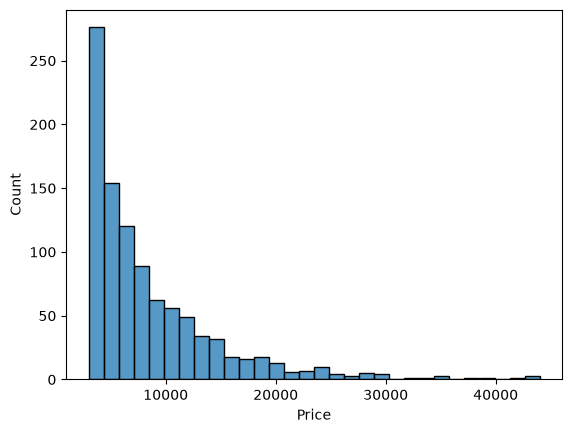

In [137]:
sns.histplot(data=df,x='Price')

<Axes: xlabel='Price'>

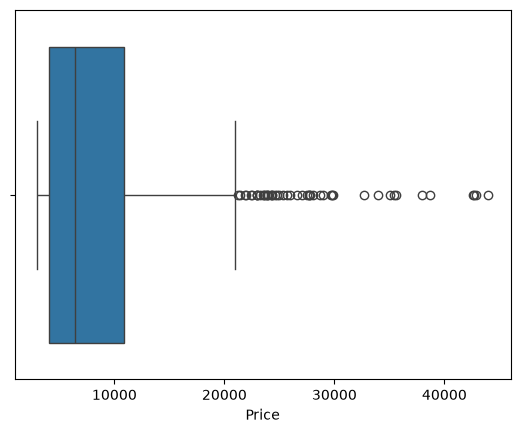

In [138]:
sns.boxplot(data=df,x='Price')

In [139]:
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 4068.0
Q3: 10917.0
IQR: 6849.0
Lower Bound: -6205.5
Upper Bound: 21190.5


In [140]:
outliers = df[df['Price'] > upper_bound]

print("Number of Outliers:", len(outliers))

Number of Outliers: 48


In [141]:
outliers['Price'].sort_values(ascending=False).head()

316    43994.0
658    42834.0
375    42655.0
280    42585.0
97     38708.0
Name: Price, dtype: float64

In [142]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(strategy='mean')
for col in ['Mileage','Engine_Size','Year']:
    df[col]=imputer.fit_transform(df[[col]])

In [143]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(strategy='most_frequent')
for col in ['Previous_Owners','Transmission','Fuel_Type','Brand']:
    df[[col]]=imputer.fit_transform(df[[col]])

In [144]:
df.duplicated().sum()

np.int64(0)

In [145]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,5,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0


<Axes: xlabel='Mileage', ylabel='Price'>

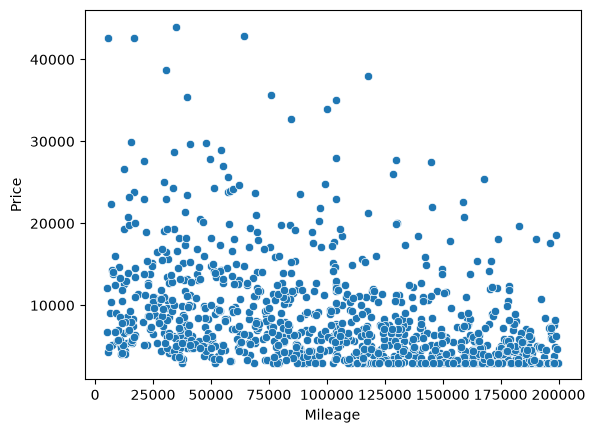

In [146]:
sns.scatterplot(data=df,x='Mileage',y='Price')

In [147]:
df['Mileage'].corr(df['Price'])

np.float64(-0.36963577123353236)

In [148]:
df.isnull().sum()

Brand              0
Year               0
Mileage            0
Engine_Size        0
Fuel_Type          0
Transmission       0
Previous_Owners    0
Price              0
dtype: int64

In [149]:
df.dtypes

Brand                  str
Year               float64
Mileage            float64
Engine_Size        float64
Fuel_Type              str
Transmission           str
Previous_Owners        str
Price              float64
dtype: object

In [150]:
df.select_dtypes(include='object').columns

C:\Users\www\AppData\Local\Temp\ipykernel_13768\3732952691.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').columns


Index(['Brand', 'Fuel_Type', 'Transmission', 'Previous_Owners'], dtype='str')

In [151]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015.0,110373.0,2.5,Electric,Manual,2,3000.0
1,Mercedes,2010.0,186144.0,1.3,Electric,Manual,5,4844.0
2,Nissan,2018.0,29574.0,2.6,Petrol,Manual,1,6628.0
3,Kia,2010.0,139502.0,2.4,Diesel,Automatic,5,3000.0
4,BMW,2014.0,148748.0,3.5,Diesel,Manual,1,6451.0


In [152]:
df.select_dtypes(include='object').nunique()

C:\Users\www\AppData\Local\Temp\ipykernel_13768\3404847108.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include='object').nunique()


Brand              8
Fuel_Type          4
Transmission       2
Previous_Owners    6
dtype: int64

In [ ]:
from sklearn.preprocessing import OneHotEncoder
OHE=OneHotEncoder(handle_unknown='ignore')
OHE_Encoded=OHE.fit_transform(df[['Brand', 'Fuel_Type', 'Transmission', 'Previous_Owners']]).toarray()
OHE_df=pd.DataFrame(OHE_Encoded,columns=OHE.get_feature_names_out(),index=df.index)
df=pd.concat([df,OHE_df],axis=1)

In [154]:
df.drop(['Brand', 'Fuel_Type', 'Transmission'],axis=1,inplace=True)

In [155]:
df.head()

,Year,Mileage,Engine_Size,Previous_Owners,Price,Brand_BMW,Brand_Honda,Brand_Hyundai,Brand_Kia,Brand_Mazda,...,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual,Previous_Owners_,Previous_Owners_1,Previous_Owners_2,Previous_Owners_3,Previous_Owners_4,Previous_Owners_5
0,2015.0,110373.0,2.5,2,3000.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
1,2010.0,186144.0,1.3,5,4844.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2018.0,29574.0,2.6,1,6628.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,2010.0,139502.0,2.4,5,3000.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2014.0,148748.0,3.5,1,6451.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0


In [159]:
df.drop('Previous_Owners',axis=1,inplace=True)

In [160]:
df.info()

<class 'pandas.DataFrame'>
Index: 987 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Year                    987 non-null    float64
 1   Mileage                 987 non-null    float64
 2   Engine_Size             987 non-null    float64
 3   Price                   987 non-null    float64
 4   Brand_BMW               987 non-null    float64
 5   Brand_Honda             987 non-null    float64
 6   Brand_Hyundai           987 non-null    float64
 7   Brand_Kia               987 non-null    float64
 8   Brand_Mazda             987 non-null    float64
 9   Brand_Mercedes          987 non-null    float64
 10  Brand_Nissan            987 non-null    float64
 11  Brand_Toyota            987 non-null    float64
 12  Fuel_Type_Diesel        987 non-null    float64
 13  Fuel_Type_Electric      987 non-null    float64
 14  Fuel_Type_Hybrid        987 non-null    float64
 15  Fuel_

In [161]:
x=df.drop(['Price'],axis=1)
y=df['Price']

In [163]:
from sklearn.model_selection import train_test_split 
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=100,stratify=None)

In [164]:
print('x_train=',x_train.shape,'y_train=',y_train.shape)
print('x_test=',x_test.shape,'y_test=',y_test.shape)

x_train= (789, 23) y_train= (789,)
x_test= (198, 23) y_test= (198,)


In [167]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train=scaler.fit_transform(x_train)
x_test=scaler.transform(x_test)

In [168]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](23,)","[ 3220.43,-2285.78, 1053.36,..., 42.91, 53.56, -60.84]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,8343
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,23
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(19)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](23,)","[40.58,34.53,33.88,..., 0. , 0. , 0. ]"


In [169]:
y_pred = model.predict(x_test)

In [170]:
from sklearn.metrics import mean_absolute_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 2364.0773455334397
R2 Score: 0.6930882972062066


In [171]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=100
)

rf_model.fit(x_train, y_train)

rf_pred = rf_model.predict(x_test)

In [172]:
print("MAE:", mean_absolute_error(y_test, rf_pred))
print("R2 Score:", r2_score(y_test, rf_pred))

MAE: 1876.5403535353535
R2 Score: 0.7667199409356535
